# Lab RAG — Designing Machine Learning Systems

Experimento de RAG sobre o livro *Designing Machine Learning Systems* (C. Huyen),
comparando três variantes de pipeline:

- **baseline** — TF-IDF + geração direta
- **adaptive** — roteamento adaptativo da consulta
- **self_rag** — reflexão e auto-avaliação do gerador

Métricas comparadas: acurácia (juiz LLM com answer key de 20 questões),
latência, número de chamadas ao LLM e estabilidade entre 3 repetições.

## Como executar
1. Instale as dependências e inicie o Ollama (células de setup)
2. Coloque o PDF do livro e o `questions.json` nos caminhos do config
3. Execute as células em ordem — resultados gravados em `results/`


## 0. Ambiente de Execução

In [ ]:
# Verificação da GPU usada na execução dos testes
import subprocess

gpu = subprocess.run(['nvidia-smi', '--query-gpu=name,memory.total',
                      '--format=csv,noheader'], capture_output=True, text=True)
if gpu.returncode == 0 and gpu.stdout.strip():
    print(f"GPU: {gpu.stdout.strip()}")
else:
    print("Nenhuma GPU detectada — execução em CPU; "
          "latências não comparáveis com a run oficial (Colab GPU).")

GPU: NVIDIA RTX PRO 6000 Blackwell Server Edition, 97887 MiB


# 1. Dependências do projeto

In [ ]:

!pip install -q pypdf pandas numpy scikit-learn requests rank_bm25 matplotlib

### Instalação e configuração do Ollama

O Ollama não vem pré-instalado no Colab. São três passos:

1. Instalar o executável (célula 2)
2. Iniciar o servidor em segundo plano — `ollama serve` (célula 3)
3. Baixar os modelos: gerador do experimento (`qwen2.5:7b`) e de embeddings (`nomic-embed-text`) (célula 4)

In [414]:
%%bash
# 1. Instalação do Ollama (runtime dos modelos locais)- CELULA 2
# zstd é dependência do instalador oficial
set -e
sudo apt-get update -qq && sudo apt-get install -y -qq zstd
curl -fsSL https://ollama.com/install.sh | sh
ollama --version

W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu noble InRelease' does not seem to provide it (sources.list entry misspelt?)
>>> Cleaning up old version at /usr/local/lib/ollama
>>> Installing ollama to /usr/local
>>> Downloading ollama-linux-amd64.tar.zst
######################################################################## 100.0%
>>> Adding ollama user to video group...
>>> Adding current user to ollama group...
>>> Creating ollama systemd service...
>>> The Ollama API is now available at 127.0.0.1:11434.
>>> Install complete. Run "ollama" from the command line.


In [415]:
# 2. Iniciar o servidor Ollama (o instalador não sobe o serviço no Colab) - CELULA 3
import subprocess, time, os, requests

subprocess.run(["pkill", "ollama"])  # idempotente: encerra instâncias de execuções anteriores
time.sleep(2)

# host explícito evita falha de resolução de interface no Colab
env = {**os.environ, "OLLAMA_HOST": "127.0.0.1:11434"}
subprocess.Popen(["ollama", "serve"], env=env,
                 stdout=subprocess.DEVNULL, stderr=subprocess.DEVNULL)

for _ in range(25):
    try:
        if requests.get("http://127.0.0.1:11434/").status_code == 200:
            print("✅ Servidor Ollama ativo em http://127.0.0.1:11434")
            break
    except requests.exceptions.ConnectionError:
        pass
    time.sleep(1)
else:
    raise RuntimeError("Ollama não subiu em 25s — verifique a célula de instalação.")

✅ Servidor Ollama ativo em http://127.0.0.1:11434


In [416]:
# 4. Download dos modelos: gerador do experimento +  - CELULA 4
if 'config' not in globals():
    raise RuntimeError("config não carregada — execute antes a célula do configs/experiment.json.")
model_name = config['generator_model']

!ollama pull {model_name}
!ollama pull nomic-embed-text   # embeddings da correção F2 (retrieval denso)

print(f"✅ '{model_name}' e 'nomic-embed-text' prontos para uso!")




✅ 'qwen2.5:7b' e 'nomic-embed-text' prontos para uso!


In [ ]:
!curl http://127.0.0.1:11434/api/generate -d '{"model":"qwen2.5:7b","prompt":"ok","stream":false}'
!curl http://127.0.0.1:11434/api/ps

{"model":"qwen2.5:7b","created_at":"2026-10-15T00:23:03.608296257Z","response":"当然，需要帮助时随时告诉我！你有什么问题或需要什么帮助吗？","done":true,"done_reason":"stop","context":[151644,8948,198,2610,525,1207,16948,11,3465,553,54364,14817,13,1446,525,264,10950,17847,13,151645,198,151644,872,198,562,151645,198,151644,77091,198,103942,3837,85106,100364,13343,102422,106525,6313,56568,104139,86119,57191,85106,99245,100364,101037,11319],"total_duration":1837613887,"load_duration":1718607999,"prompt_eval_count":30,"prompt_eval_cached_count":0,"prompt_eval_duration":41402000,"eval_count":18,"eval_duration":76020000}{"models":[{"name":"qwen2.5:7b","model":"qwen2.5:7b","size":6608251780,"digest":"845dbda0ea48ed749caafd9e6037047aa19acfcfd82e704d7ca97d631a0b697e","details":{"parent_model":"","format":"gguf","family":"qwen2","families":["qwen2"],"parameter_size":"7.6B","quantization_level":"Q4_K_M"},"expires_at":"2026-10-15T00:28:03.608832907Z","size_vram":6608251780,"context_length":32768,"runner":"llamacpp"}]}

## Configuração do experimento

Localiza a raiz do projeto (`find_root()` — funciona no Colab e em execução local,
buscando a pasta que contém `questions.json` + `experiment.json`) e carrega:

- `experiment.json` — modelos, top_k, parâmetros de chunking
- `questions.json` — 20 questões com categoria e dificuldade

Localiza o PDF do livro
(`find_pdf_path()` — busca em `corpus/documentos/`, raiz do projeto e `/content`).

Valida a estrutura dos arquivos antes de qualquer execução — erros de
configuração aparecem aqui, não no meio do experimento.

In [417]:
# Configuração do projeto: imports, config e localização do corpus - CELULA 5
import json
from pathlib import Path

import time
import hashlib
from datetime import datetime, timezone

import numpy as np
import pandas as pd
import requests
from pypdf import PdfReader
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

def find_root():
    """Localiza a raiz do projeto (Colab ou execução local)."""
    def has_markers(c):
        if not (c / 'questions.json').exists():
            return False
        return ((c / 'experiment.json').exists()
                or (c / 'configs' / 'experiment.json').exists())

    bases = [Path.cwd(), Path('/content')]
    candidates = list(bases)
    for base in bases:
        if base.exists():
            candidates.extend(p.parent for p in base.glob('*/questions.json'))
            candidates.extend(p.parent for p in base.glob('*/*/questions.json'))
    candidates.extend(Path.cwd().parents)  # notebook aberto em subpasta
    for c in candidates:
        if has_markers(c):
            return c
    return Path.cwd()

ROOT = find_root()

def load_json(path):
    if not path.exists():
        raise FileNotFoundError(
            f'Arquivo não encontrado: {path}\n'
            'No Colab: suba questions.json e experiment.json na raiz do projeto.'
        )
    with open(path, 'r', encoding='utf-8') as fh:
        return json.load(fh)

# experiment.json na raiz ou em configs/
if (ROOT / 'experiment.json').exists():
    CONFIG_PATH = ROOT / 'experiment.json'
elif (ROOT / 'configs' / 'experiment.json').exists():
    CONFIG_PATH = ROOT / 'configs' / 'experiment.json'
else:
    CONFIG_PATH = ROOT / 'experiment.json'

QUESTIONS_PATH = ROOT / 'questions.json'
config = load_json(CONFIG_PATH)
questions = load_json(QUESTIONS_PATH)

# validação mínima da estrutura das perguntas
assert questions.get('questions'), "questions.json não contém a lista 'questions'."
required_q = {'id', 'question', 'category', 'difficulty', 'answer_key'}
missing = [k for k in required_q if k not in questions['questions'][0]]
assert not missing, f"Campos ausentes nas perguntas: {missing}"

def find_pdf_path(root=None):
    """Localiza o PDF do livro: corpus/documentos/, raiz do projeto ou /content (Colab)."""
    root = Path(root or ROOT)
    folders = [root / 'corpus' / 'documentos', root, Path('/content')]
    searched = []
    for folder in folders:
        if not folder.exists():
            continue
        searched.append(str(folder))
        matches = sorted(p for p in folder.rglob('*.pdf')
                         if not p.name.startswith(('.', '~', '$')))
        if matches:
            if len(matches) > 1:
                print(f'Vários PDFs em {folder}; usando o primeiro: {matches[0].name}')
            return matches[0]
    raise FileNotFoundError(
        'PDF do livro não encontrado. Pastas verificadas: ' + '; '.join(searched)
        + '. Coloque o PDF em corpus/documentos/ ou na raiz do projeto (/content no Colab).'
    )

pdf_path = find_pdf_path(ROOT)

print(f"Projeto: {config.get('project_name', 'rag-dmls-lab')}")
print(f"Perguntas carregadas: {len(questions['questions'])}")
print(f"Tema: {config.get('topic', 'Designing Machine Learning Systems')}")
print(f"ROOT: {ROOT}")
print(f"PDF: {pdf_path}")

Projeto: rag-dmls-lab
Perguntas carregadas: 20
Tema: Designing Machine Learning Systems
ROOT: /content
PDF: /content/designing-machine-learning-systems-2022.pdf


## Corpus: leitura e chunking

`read_pdf_pages()` extrai o texto de todas as páginas do PDF e
`chunk_text()` divide o texto em blocos de tamanho fixo com sobreposição.
Os valores padrão (800/120) espelham o `experiment.json` — fonte única
dos parâmetros de chunking.

In [418]:
def read_pdf_pages(pdf_path):
    """Retorna lista de (numero_real_da_pagina, texto) apenas para páginas com texto."""
    reader = PdfReader(pdf_path)
    pages = []
    for page_num, page in enumerate(reader.pages, start=1):
        text = re.sub(r'\s+', ' ', page.extract_text() or '').strip()
        if text:
            pages.append((page_num, text))
    return pages

def chunk_pages_with_source(pages, chunk_size=800, overlap=120):
    """pages: lista de (numero_real, texto). Retorna (chunks, chunk_pages) com a página real."""
    _validate_chunk_params(chunk_size, overlap)
    full_text, page_starts = '', []
    for page_num, page_text in pages:
        page_starts.append((len(full_text), page_num))
        full_text += page_text + ' '

    chunks, chunk_pages = [], []
    step = chunk_size - overlap
    for start in range(0, len(full_text), step):
        piece = full_text[start:start + chunk_size].strip()
        if piece:
            page = max(num for pos, num in page_starts if pos <= start)
            chunks.append(piece)
            chunk_pages.append(page)
        if start + chunk_size >= len(full_text):
            break
    return chunks, chunk_pages

pages = read_pdf_pages(pdf_path)
chunks, chunk_pages = chunk_pages_with_source(pages, chunk_size=800, overlap=120)

print(f"Páginas com texto: {len(pages)}")
print(f"Chunks gerados: {len(chunks)}")
print(f"Exemplo (página {chunk_pages[0]}): {chunks[0][:120]}...")

Páginas com texto: 313
Chunks gerados: 713
Exemplo (página 2): Designing Machine Learning Systems An Iterative Process for Production-Ready Applications With Early Release ebooks, you...


## Corpus: extração e chunking

Extrai o texto de todas as páginas do PDF e divide em chunks com os
parâmetros do `experiment.json` (`chunk_size_chars`, `chunk_overlap_chars`).
Os chunks gerados alimentam os retrievers das três variantes do experimento.

In [419]:
# 7. Chunking do corpus com página de origem (usa os parâmetros do config) - CÉLULA 7
pages = read_pdf_pages(pdf_path)  # lista de (numero_real_da_pagina, texto)

chunk_size = config['chunk_size_chars']
overlap = config['chunk_overlap_chars']
chunks, chunk_pages = chunk_pages_with_source(pages, chunk_size=chunk_size, overlap=overlap)

print(f"Páginas com texto: {len(pages)}")
print(f"Chunks gerados: {len(chunks)} (chunk_size={chunk_size}, overlap={overlap})")
print(f"Página do primeiro chunk: {chunk_pages[0]}")

Páginas com texto: 313
Chunks gerados: 713 (chunk_size=800, overlap=120)
Página do primeiro chunk: 2


In [420]:
# 8. Índice de retrieval do baseline: TF-IDF - CELULA 8
def build_index(chunks):
    """Constrói o índice TF-IDF do baseline (unigramas e bigramas)."""
    vectorizer = TfidfVectorizer(stop_words='english', ngram_range=(1, 2))
    matrix = vectorizer.fit_transform(chunks)
    return vectorizer, matrix

vectorizer, matrix = build_index(chunks)
print(f"Índice TF-IDF: {matrix.shape[0]} chunks × {matrix.shape[1]} termos de vocabulário")

Índice TF-IDF: 713 chunks × 37800 termos de vocabulário


## Funções de retrieval, prompt e roteamento

- `expand_query()` + `retrieve_top_k()` — retriever esparso do baseline: expande a
  query com termos do domínio e retorna os top-k chunks por similaridade de cosseno
- `format_prompt()` — monta o prompt com a questão e o contexto recuperado
- `route_question()` — roteador heurístico da variante adaptativa: questões de
  sistema, arquitetura e monitoramento seguem para o pipeline adaptativo

In [421]:
# 8. Funções de retrieval, prompt e roteamento - CÉLULA 8
import re

def expand_query(query):
    """Expande a query com termos do domínio do livro.
    Usada apenas pelo Adaptive RAG (via adaptive_retrieve)."""
    expansions = {
        'business value': 'business objective success metric problem framing use case',
        'clear definition of the problem': 'problem framing task definition objective success criteria',
        'data-centric approach': 'data-centric AI data quality labels dataset improvement',
        'model-centric approach': 'model-centric AI algorithm architecture model improvement',
        'real-world performance': 'production performance deployment distribution shift noisy inputs',
        'feedback loops': 'degenerate feedback loops popularity bias production predictions',
    }
    lowered = query.lower()
    return ' '.join([query] + [v for key, v in expansions.items() if key in lowered])

def retrieve_top_k(query, chunks, vectorizer, matrix, k, expand=True):
    """Retorna os top-k chunks por similaridade de cosseno.
    expand=True aplica expand_query (Adaptive); expand=False usa a query original
    (Baseline e Self-RAG)."""
    text = expand_query(query) if expand else query
    q_vector = vectorizer.transform([text])
    scores = cosine_similarity(q_vector, matrix).ravel()
    ranked = [idx for idx in np.argsort(scores)[::-1] if scores[idx] > 0][:k]
    return [(chunks[idx], float(scores[idx])) for idx in ranked]

def format_prompt(question, context):
    """Prompt de resposta. Exige inglês e evidência explícita."""
    return (
        'Answer the question using only the provided context. '
        'Answer in English. If the context does not contain enough evidence, say so explicitly.\n\n'
        f'Question: {question}\n\nContext:\n{context}\n\nAnswer:'
    )

# Padrões com fronteira de palavra. Cada padrão casa a palavra inteira (ou a
# forma flexionada prevista), não um pedaço dentro de outra palavra.
ADAPTIVE_PATTERNS = [
    r'\bcompar\w*',
    r'\btrade-?offs?\b',
    r'\barchitectures?\b',
    r'\bdesign(?:s|ing|ed)?\b',
    r'\bmonitor(?:s|ing)?\b',
    r'\blatenc(?:y|ies)\b',
    r'\bcosts?\b',
    r'\bobservabilit\w*',
    r'\bsystems?\b',
    r'\bserving\b',
]

def route_question(question):
    """Roteador heurístico: 'adaptive' se a pergunta tiver algum marcador, senão 'baseline'."""
    q = question.lower()
    return 'adaptive' if any(re.search(p, q) for p in ADAPTIVE_PATTERNS) else 'baseline'

## Geração: chamada ao LLM e pipelines de resposta

- `call_ollama()` — chamada à API local do Ollama, com modelo e temperatura
  do `experiment.json`
- `adaptive_retrieve()` — retrieval da variante adaptativa: expansão da query,
  queries extras para questões de sistema e deduplicação de passages
- `answer_question_baseline()` / `answer_question_adaptive()` — montam o prompt
  com o contexto recuperado (ou recebem os hits já calculados) e geram a resposta

In [422]:
import re
import inspect
import requests

OLLAMA_URL = 'http://127.0.0.1:11434/api/generate'

# Log do Self-RAG: question -> lista de metas (uma por repetição).
# Esvaziado na célula de run antes de cada execução oficial.
SELF_RAG_LOG = {}

def parse_verdict(raw):
    """Interpreta o veredito do verificador de forma robusta.
    Retorna 'SUPPORTED', 'NOT_SUPPORTED' ou 'PARSE_ERROR'."""
    clean_raw = raw.upper().replace('-', '_').replace(' ', '_')
    if 'NOT_SUPPORTED' in clean_raw:
        return 'NOT_SUPPORTED'
    if 'SUPPORTED' in clean_raw:
        return 'SUPPORTED'
    return 'PARSE_ERROR'

def call_ollama(prompt, model=None, temperature=None, timeout=120):
    payload = {
        'model': model or config['generator_model'],
        'prompt': prompt,
        'stream': False,
        'options': {
            'temperature': temperature if temperature is not None
                           else config['generation_temperature'],
            'seed': config.get('seed', 42),
        },
    }
    response = requests.post(OLLAMA_URL, json=payload, timeout=timeout)
    response.raise_for_status()
    return response.json().get('response', '').strip()

def build_context(passages):
    """Monta o bloco de contexto numerado a partir dos passages recuperados."""
    return '\n\n---\n\n'.join(
        f'[Passage {i + 1}] {text[:1600]}' for i, (text, _) in enumerate(passages)
    )

def retrieve_top_k(query, chunks, vectorizer, matrix, k, expand=True):
    """Retorna os top-k chunks por similaridade de cosseno.
    expand=True aplica expand_query (Adaptive); expand=False usa a query original."""
    text = expand_query(query) if expand else query
    q_vector = vectorizer.transform([text])
    scores = cosine_similarity(q_vector, matrix).ravel()
    ranked = [idx for idx in np.argsort(scores)[::-1] if scores[idx] > 0][:k]
    return [(chunks[idx], float(scores[idx])) for idx in ranked]

def rrf_fuse(ranked_lists, k, c=60):
    """Reciprocal Rank Fusion: funde rankings de várias consultas."""
    scores, texts = {}, {}
    for lst in ranked_lists:
        for rank, (text, _) in enumerate(lst, start=1):
            key = text[:200]
            scores[key] = scores.get(key, 0.0) + 1.0 / (c + rank)
            texts.setdefault(key, text)
    ordered = sorted(scores, key=scores.get, reverse=True)[:k]
    return [(texts[key], scores[key]) for key in ordered]

def adaptive_retrieve(question, chunks, vectorizer, matrix, k):
    """Adaptive v1: expansão de consulta + (se roteado) consultas extras, fundidas por RRF."""
    variants = [expand_query(question)]
    if route_question(question) == 'adaptive':
        variants.extend([
            'trade-offs in designing machine learning systems',
            'monitoring, evaluation and operational constraints in ML',
            'data quality and deployment considerations in ML systems',
        ])
    ranked_lists = [
        retrieve_top_k(v, chunks, vectorizer, matrix, k=k, expand=False) for v in variants
    ]
    return rrf_fuse(ranked_lists, k)

def answer_question_baseline(question, chunks, vectorizer, matrix, k=None, model=None, hits=None):
    k = k or config['top_k']
    hits = hits if hits is not None else retrieve_top_k(
        question, chunks, vectorizer, matrix, k=k, expand=False)
    if not hits:
        return 'Não encontrei evidência suficiente no corpus para responder com confiança.'
    prompt = format_prompt(question, build_context(hits[:k]))
    try:
        return call_ollama(prompt, model=model)
    except Exception as exc:
        return f'Erro ao chamar o Ollama: {exc}'

def answer_question_adaptive(question, chunks, vectorizer, matrix, k=None, model=None, hits=None):
    k = k or config['top_k']
    context_parts = hits if hits is not None else adaptive_retrieve(question, chunks, vectorizer, matrix, k)
    if not context_parts:
        return 'Não encontrei evidência suficiente no corpus para responder com confiança.'
    prompt = format_prompt(question, build_context(context_parts[:k]))
    try:
        return call_ollama(prompt, model=model)
    except Exception as exc:
        return f'Erro ao chamar o Ollama: {exc}'

def answer_question_self_rag(question, chunks, vectorizer, matrix, k=None, model=None, hits=None):
    """Self-RAG: rascunho -> verificação -> (se NOT_SUPPORTED) nova geração com instrução
    de usar só o contexto. Mesma retrieval do baseline (sem expansão). Até 3 chamadas."""
    k = k or config['top_k']
    context_parts = hits if hits is not None else retrieve_top_k(
        question, chunks, vectorizer, matrix, k=k, expand=False)
    context_parts = context_parts[:k]

    if not context_parts:
        SELF_RAG_LOG.setdefault(question, []).append(
            {'draft_verdict': 'NO_CONTEXT', 'revised': False, 'llm_calls': 0, 'verifier_raw': None})
        return 'Não encontrei evidência suficiente no corpus para responder com confiança.'

    context = build_context(context_parts)
    calls, verifier_raw = 0, None
    try:
        draft = call_ollama(format_prompt(question, context), model=model)
        calls += 1

        verifier_raw = call_ollama(
            "You are a strict verifier. Decide if the DRAFT (1) is fully supported "
            "by the CONTEXT and (2) answers the QUESTION.\n"
            "Reply with exactly one word: SUPPORTED or NOT_SUPPORTED. No explanation.\n\n"
            f"QUESTION: {question}\n\n"
            f"CONTEXT:\n{context}\n\n"
            f"DRAFT: {draft}\n\n"
            "VERDICT:",
            model=model,
        )
        calls += 1
        verdict = parse_verdict(verifier_raw)

        if verdict == 'NOT_SUPPORTED':
            answer = call_ollama(
                format_prompt(question, context)
                + "\n\nYour previous draft was not fully supported by the context. "
                  "Answer again using ONLY facts present in the context. If the "
                  "context does not contain the answer, say you do not know.",
                model=model,
            )
            calls += 1
            meta = {'draft_verdict': 'NOT_SUPPORTED', 'revised': True}
        else:
            answer = draft
            meta = {'draft_verdict': verdict, 'revised': False}
    except Exception as exc:
        SELF_RAG_LOG.setdefault(question, []).append(
            {'draft_verdict': 'CALL_ERROR', 'revised': False,
             'llm_calls': calls, 'verifier_raw': verifier_raw})
        return f'Erro ao chamar o Ollama: {exc}'

    meta.update(llm_calls=calls, verifier_raw=(verifier_raw or '')[:200])
    SELF_RAG_LOG.setdefault(question, []).append(meta)
    return answer

# verificação de que o patch está ativo (falha aqui, não na run)
assert 'rrf_fuse' in inspect.getsource(adaptive_retrieve), 'Patch RRF não ativo'
assert "'seed'" in inspect.getsource(call_ollama), 'Seed não ativo'
print('Patch final ativo: RRF no Adaptive e seed no Ollama.')

Patch final ativo: RRF no Adaptive e seed no Ollama.


## Smoke test

Executa as 5 primeiras questões pelo pipeline completo (roteamento → retrieval → LLM)
e valida o resultado em memória: respostas não vazias, nenhum erro de chamada ao
Ollama, latências válidas. A run oficial só é executada depois deste teste passar.

In [425]:
def run_smoke_test(n=5):
    SELF_RAG_LOG.clear()
    results = []
    for item in questions['questions'][:n]:
        question = item['question']
        for variant, answer_fn in (
            ('baseline', answer_question_baseline),
            ('adaptive', answer_question_adaptive),
            ('self_rag', answer_question_self_rag),
        ):
            start = time.perf_counter()
            hits = official_hits(question, chunks, vectorizer, matrix, variant)
            answer = answer_fn(question, chunks, vectorizer, matrix, hits=hits)
            results.append({
                'id': item['id'],
                'variant': variant,
                'latency_sec': round(time.perf_counter() - start, 3),
                'answer': answer,
            })
    return pd.DataFrame(results)

sample_df = run_smoke_test()
assert sample_df['latency_sec'].between(0, 600).all(), (
    f"Latência fora do intervalo: {sample_df['latency_sec'].tolist()}"
)
print(sample_df.groupby('variant')['latency_sec'].describe())

_n = min(5, len(questions['questions']))

# respostas
assert len(sample_df) == 3 * _n
assert sample_df['answer'].str.strip().ne('').all(), 'Smoke test produziu resposta vazia.'
assert not sample_df['answer'].str.startswith('Erro ao chamar o Ollama').any(), (
    'Smoke test falhou: o Ollama não respondeu — verifique a célula 3.'
)
assert sample_df['latency_sec'].ge(0).all()

# log do Self-RAG: uma entrada por questão, com campos completos
_entries = [meta for entries in SELF_RAG_LOG.values() for meta in entries]
assert len(_entries) == _n, f'SELF_RAG_LOG com {len(_entries)} entradas; esperava {_n}.'

for meta in _entries:
    assert 'llm_calls' in meta and 'verifier_raw' in meta, f'Campos ausentes: {meta}'

# PARSE_ERROR reprova o smoke: indica formato do verificador fora do contrato
_verdicts = [m['draft_verdict'] for m in _entries]
assert set(_verdicts) <= {'SUPPORTED', 'NOT_SUPPORTED'}, (
    f'Vereditos inválidos no smoke: {sorted(set(_verdicts))}. '
    'Verifique verifier_raw no SELF_RAG_LOG antes da run oficial.'
)

# fluxo: 2 chamadas sem revisão, 3 com revisão; revisão só quando NOT_SUPPORTED
for m in _entries:
    esperado = 3 if m['draft_verdict'] == 'NOT_SUPPORTED' else 2
    assert m['llm_calls'] == esperado, f'llm_calls={m["llm_calls"]}, esperado {esperado}: {m}'
    assert m['revised'] == (m['draft_verdict'] == 'NOT_SUPPORTED'), f'revised inconsistente: {m}'

_revisoes = sum(m['revised'] for m in _entries)
print(f'SMOKE TEST PASSOU: {len(sample_df)} respostas em memória; nenhum arquivo oficial gerado.')
print(f'Self-RAG: {_n} execuções | vereditos: {sorted(set(_verdicts))} | revisões: {_revisoes}')
print(f'llm_calls por execução: {[m["llm_calls"] for m in _entries]}')
display(sample_df.head())


          count    mean       std    min    25%    50%    75%    max
variant                                                             
adaptive    5.0  0.3992  0.095445  0.259  0.357  0.410  0.476  0.494
baseline    5.0  0.5218  0.112853  0.365  0.495  0.518  0.552  0.679
self_rag    5.0  0.5514  0.114553  0.398  0.510  0.551  0.585  0.713
SMOKE TEST PASSOU: 15 respostas em memória; nenhum arquivo oficial gerado.
Self-RAG: 5 execuções | vereditos: ['SUPPORTED'] | revisões: 0
llm_calls por execução: [2, 2, 2, 2, 2]


,id,variant,latency_sec,answer
0,Q01,baseline,0.495,The book emphasizes starting with data quality...
1,Q01,adaptive,0.476,The book emphasizes starting with data quality...
2,Q01,self_rag,0.510,The book emphasizes starting with data quality...
3,Q02,baseline,0.679,The book describes a debate within the machine...
4,Q02,adaptive,0.494,The book describes a debate in the ML literatu...


## Experimento oficial

Execute esta seção somente depois que o **SMOKE TEST PASSOU**.

A execução oficial percorre as 20 perguntas, respeita as repetições definidas
em `configs/experiment.json` e grava CSVs, traces JSONL e um manifesto em
`results/`. Diferentemente da demonstração, estes arquivos são resultados
persistentes e versionáveis. A função abaixo não é chamada automaticamente.

In [432]:
# 11. Experimento oficial: execução das variantes, traces e manifesto CELULA 11
import inspect, hashlib, json, time
from datetime import datetime, timezone
import pandas as pd

RESULTS_DIR = ROOT / 'results'
TRACES_DIR = RESULTS_DIR / 'traces'

# --- Pré-verificações: falham antes de gastar tempo com o Ollama ---
assert 'rrf_fuse' in globals(), 'rrf_fuse não aplicado'
assert 'expand' in retrieve_top_k.__code__.co_varnames, 'retrieve_top_k sem parâmetro expand'
assert len(questions['questions']) == config['question_count'], 'Quantidade de perguntas diverge do config'

# --- Contador de chamadas ao LLM (guarda evita contagem dupla se a célula for reexecutada) ---
if '_call_ollama_original' not in globals():
    _call_ollama_original = call_ollama
CALL_COUNTER = {'n': 0}

def call_ollama(prompt, *args, **kwargs):
    CALL_COUNTER['n'] += 1
    return _call_ollama_original(prompt, *args, **kwargs)

def warmup():
    """Chamada descartável: estabiliza o estado do servidor antes de cada variante."""
    call_ollama('Reply with the single word: OK.')

def sha256_file(path):
    digest = hashlib.sha256()
    with open(path, 'rb') as fh:
        for block in iter(lambda: fh.read(1024 * 1024), b''):
            digest.update(block)
    return digest.hexdigest()

def official_hits(question, chunks, vectorizer, matrix, variant):
    """Recuperação usada pelo pipeline da variante."""
    k = config['top_k']
    if variant == 'adaptive':
        return adaptive_retrieve(question, chunks, vectorizer, matrix, k)[:k]
    # baseline e self_rag: sem expansão, como definido na célula 8
    return retrieve_top_k(question, chunks, vectorizer, matrix, k=k, expand=False)

def run_official_experiment():
    RESULTS_DIR.mkdir(exist_ok=True)
    TRACES_DIR.mkdir(exist_ok=True)
    SELF_RAG_LOG.clear()  # log fresco: cada run oficial recomeça do zero

    dataset = questions['questions']
    all_rows = []
    variants = {
        'baseline': config['baseline_repetitions'],
        'adaptive': config['adaptive_repetitions'],
        'self_rag': config.get('self_rag_repetitions', config['baseline_repetitions']),
    }
    trace_path = TRACES_DIR / 'official_runs.jsonl'
    with open(trace_path, 'w', encoding='utf-8') as trace_file:
        for variant, repetitions in variants.items():
            warmup()  # equaliza a condição do servidor antes de cada bloco
            variant_rows = []
            for repetition in range(1, repetitions + 1):
                repetition_rows = []
                for item in dataset:
                    question = item['question']
                    CALL_COUNTER['n'] = 0  # zera antes da recuperação, que pode chamar o LLM
                    start = time.perf_counter()
                    hits = official_hits(question, chunks, vectorizer, matrix, variant)
                    answer = ANSWER_FNS[variant](question, chunks, vectorizer, matrix, hits=hits)
                    latency = round(time.perf_counter() - start, 3)
                    llm_calls = CALL_COUNTER['n']

                    evidence = [
                        {'rank': rank, 'score': round(score, 6), 'text': text}
                        for rank, (text, score) in enumerate(hits, start=1)
                    ]
                    row = {
                        'question_id': item['id'],
                        'category': item['category'],
                        'difficulty': item['difficulty'],
                        'variant': variant,
                        'repetition': repetition,
                        'route_question': route_question(question),
                        'latency_sec': latency,
                        'evidence_count': len(evidence),
                        'llm_calls': llm_calls,
                        'answer': answer,
                    }
                    if variant == 'self_rag':
                        meta = SELF_RAG_LOG[question][-1]  # última entrada = esta repetição
                        assert meta['llm_calls'] == llm_calls, (
                            f"llm_calls divergente em {item['id']}: "
                            f"contador={llm_calls}, log={meta['llm_calls']}"
                        )
                        row['draft_verdict'] = meta['draft_verdict']
                        row['revised'] = meta['revised']
                        row['verifier_raw'] = meta['verifier_raw']

                    repetition_rows.append(row)
                    variant_rows.append(row)
                    all_rows.append(row)
                    trace_file.write(json.dumps(
                        {**row, 'question': question, 'evidence': evidence},
                        ensure_ascii=False) + '\n')

                if variant in ('baseline', 'self_rag'):
                    pd.DataFrame(repetition_rows).to_csv(
                        RESULTS_DIR / f'{variant}_r{repetition}.csv', index=False)

            if variant == 'adaptive':
                pd.DataFrame(variant_rows).to_csv(
                    RESULTS_DIR / 'results_adaptive.csv', index=False)

    results_df = pd.DataFrame(all_rows)
    results_df.groupby(['variant', 'category', 'repetition'], as_index=False).agg(
        mean_latency_sec=('latency_sec', 'mean'),
        mean_evidence_count=('evidence_count', 'mean'),
        mean_llm_calls=('llm_calls', 'mean'),
        questions=('question_id', 'count'),
    ).to_csv(RESULTS_DIR / 'summary.csv', index=False)

    # divergências entre as três variantes (primeira repetição de cada uma)
    first_answers = pd.DataFrame({
        variant: results_df[results_df['variant'] == variant]
            .groupby('question_id')['answer'].first()
        for variant in variants
    })
    first_answers['answers_differ'] = first_answers.nunique(axis=1) > 1
    first_answers.reset_index().to_csv(RESULTS_DIR / 'disagreements.csv', index=False)

    manifest = {
        'created_at_utc': datetime.now(timezone.utc).isoformat(),
        'config': config,
        'config_sha256': sha256_file(CONFIG_PATH),
        'questions_sha256': sha256_file(QUESTIONS_PATH),
        'corpus_pdf': str(pdf_path.relative_to(ROOT)),
        'corpus_sha256': sha256_file(pdf_path),
        'question_count': len(dataset),
        'chunk_count': len(chunks),
        'variants': variants,
        'warmup_per_variant': True,
        'trace_file': str(trace_path.relative_to(ROOT)),
        'fusion_function': 'rrf_fuse',
        'fusion_signature': str(inspect.signature(rrf_fuse)),
        'adaptive_patterns': [getattr(p, 'pattern', str(p)) for p in ADAPTIVE_PATTERNS],
        'route_list': {q['id']: route_question(q['question']) for q in dataset},
        'seed_config': config.get('seed'),
    }
    with open(RESULTS_DIR / 'run_manifest.json', 'w', encoding='utf-8') as fh:
        json.dump(manifest, fh, ensure_ascii=False, indent=2)

    print(f'EXPERIMENTO OFICIAL CONCLUÍDO: {len(results_df)} respostas gravadas em {RESULTS_DIR}.')
    print(results_df.groupby('variant').size().to_string())
    print(results_df.groupby('variant')['llm_calls'].agg(['min', 'mean', 'max']).to_string())
    return results_df

In [433]:
# Execução oficial do experimento para persistir os resultados
official_df = run_official_experiment()

# Exportação das execuções individuais por repetição
out = RESULTS_DIR / 'por_repeticao'
out.mkdir(exist_ok=True)
for v in ['baseline', 'adaptive', 'self_rag']:
    for r in [1, 2, 3]:
        sub_df = official_df[(official_df['variant'] == v) & (official_df['repetition'] == r)]
        if not sub_df.empty:
            sub_df.to_csv(out / f'{v}_r{r}.csv', index=False)

print("\nArquivos gerados com sucesso no diretório de resultados:")
for p in sorted(RESULTS_DIR.glob('**/*.csv')):
    print(f"- {p.relative_to(ROOT)}")

EXPERIMENTO OFICIAL CONCLUÍDO: 180 respostas gravadas em /content/results.
variant
adaptive    60
baseline    60
self_rag    60
          min  mean  max
variant                 
adaptive    1   1.0    1
baseline    1   1.0    1
self_rag    2   2.3    3

Arquivos gerados com sucesso no diretório de resultados:
- results/baseline_r1.csv
- results/baseline_r2.csv
- results/baseline_r3.csv
- results/disagreements.csv
- results/por_repeticao/adaptive_r1.csv
- results/por_repeticao/adaptive_r2.csv
- results/por_repeticao/adaptive_r3.csv
- results/por_repeticao/baseline_r1.csv
- results/por_repeticao/baseline_r2.csv
- results/por_repeticao/baseline_r3.csv
- results/por_repeticao/self_rag_r1.csv
- results/por_repeticao/self_rag_r2.csv
- results/por_repeticao/self_rag_r3.csv
- results/results_adaptive.csv
- results/self_rag_r1.csv
- results/self_rag_r2.csv
- results/self_rag_r3.csv
- results/summary.csv


In [436]:
SELF_RAG_LOG.clear()

In [442]:
import inspect
assert 'expand' in inspect.signature(retrieve_top_k).parameters, 'retrieve_top_k sem expand'
assert 'rrf_fuse' in inspect.getsource(adaptive_retrieve), 'RRF inativo'
fn_to_check = globals().get('_call_ollama_original', call_ollama)
assert 'seed' in inspect.getsource(fn_to_check), 'seed inativo'
assert 'variant' in inspect.signature(official_hits).parameters, 'official_hits antiga'
assert len(questions['questions']) == config['question_count'] == 20
assert len(SELF_RAG_LOG) == 0, 'SELF_RAG_LOG não está vazio'
print('Pré-voo OK | chunks:', len(chunks), '| perguntas:', len(questions['questions']))

Pré-voo OK | chunks: 713 | perguntas: 20


## Execução do experimento oficial

Chama `run_official_experiment()` — a run completa (180 respostas) e
`official_df` fica disponível para as análises seguintes.

In [ ]:
# 12. Execução do experimento oficial - CÉLULA 12
official_df = run_official_experiment()

# Exportação por repetição (não reexecuta o modelo; só reorganiza official_df)
out = RESULTS_DIR / 'por_repeticao'
out.mkdir(exist_ok=True)
for v in ['baseline', 'adaptive', 'self_rag']:
    for r in [1, 2, 3]:
        official_df[(official_df['variant'] == v) & (official_df['repetition'] == r)] \
            .to_csv(out / f'{v}_r{r}.csv', index=False)
print(sorted(p.name for p in out.glob('*.csv')))

official_df.head()

EXPERIMENTO OFICIAL CONCLUÍDO: 180 respostas gravadas em /content/results.
variant
adaptive    60
baseline    60
self_rag    60
['adaptive_r1.csv', 'adaptive_r2.csv', 'adaptive_r3.csv', 'baseline_r1.csv', 'baseline_r2.csv', 'baseline_r3.csv', 'self_rag_r1.csv', 'self_rag_r2.csv', 'self_rag_r3.csv']


,question_id,category,difficulty,variant,repetition,route,latency_sec,evidence_count,answer,draft_verdict,revised,llm_calls,verifier_raw
0,Q01,ml_system_design,easy,baseline,1,baseline,0.440,4,The book emphasizes starting with data quality...,NaN,NaN,NaN,NaN
1,Q02,data_centricity,easy,baseline,1,adaptive,0.633,4,The book describes a debate in the ML communit...,NaN,NaN,NaN,NaN
2,Q03,baselines,easy,baseline,1,adaptive,0.355,4,Building a simple baseline is essential before...,NaN,NaN,NaN,NaN
3,Q04,data_quality,medium,baseline,1,adaptive,0.684,4,Data quality problems such as label noise and ...,NaN,NaN,NaN,NaN
4,Q05,distribution_shift,medium,baseline,1,adaptive,0.591,4,Hidden feedback loops are a type of degenerate...,NaN,NaN,NaN,NaN


## Grader de acurácia

Avalia cada resposta do experimento oficial contra a answer key do
`questions.json` usando um juiz LLM com contrato de 1 palavra
(CORRECT/INCORRECT — padrão da lição 07). Produz `accuracy.csv` (veredito
por resposta) e `accuracy_summary.csv` (acurácia por variante), e mostra
os recortes por dificuldade e as questões com veredito divergente.

In [454]:
# 13. Grader de acurácia — contrato de 1 palavra - CELULA 13
# Requisito: questions.json com 'answer_key' em cada questão.
# Avalia todas as respostas do experimento oficial:
# 180 = 3 variantes × 3 repetições × 20 questões.

# recuperação: se a sessão reiniciou, reexecute as células 1-11
# e este bloco reconstrói o official_df a partir dos CSVs gravados
import re

try:
    official_df
except NameError:
    _files = ([RESULTS_DIR / f'baseline_r{r}.csv' for r in (1, 2, 3)]
              + [RESULTS_DIR / 'results_adaptive.csv']
              + [RESULTS_DIR / f'self_rag_r{r}.csv' for r in (1, 2, 3)])
    _faltando = [str(f) for f in _files if not f.exists()]
    assert not _faltando, (
        f"CSVs ausentes: {_faltando}. "
        "Execute a run oficial (célula 12) antes do grader."
    )
    official_df = pd.concat([pd.read_csv(f) for f in _files], ignore_index=True)
    print(f'official_df reconstruído: {len(official_df)} respostas')
    print(official_df['variant'].value_counts().to_string())

# 0) completude da run: cada variante com questões × repetições respostas
_expected_reps = {
    'baseline': config['baseline_repetitions'],
    'adaptive': config['adaptive_repetitions'],
    'self_rag': config.get('self_rag_repetitions', config['baseline_repetitions']),
}
for _variant, _reps in _expected_reps.items():
    _got = len(official_df[official_df['variant'] == _variant])
    _want = len(questions['questions']) * _reps
    assert _got == _want, (
        f'Run incompleta para {_variant}: {_got} respostas (esperado {_want}). '
        'Reexecute a célula 12 antes do grader.'
    )
JUDGE_MODEL = 'llama3.1:8b'  # tag exata de `ollama list`

def parse_verdict(raw):
    m = re.search(r'\b(INCORRECT|NOT CORRECT|CORRECT)\b', raw.upper())
    if not m:
        return 'PARSE_ERROR'
    return 'CORRECT' if m.group(1) == 'CORRECT' else 'INCORRECT'

# 1) valida a answer key antes de gastar chamadas
ANSWER_KEY_FIELDS = ('answer_key', 'answer', 'expected_answer')
q_map, key_map, missing_keys = {}, {}, []
for item in questions['questions']:
    q_map[item['id']] = item
    key = next((str(item[f]).strip() for f in ANSWER_KEY_FIELDS if item.get(f)), None)
    if key is None:
        missing_keys.append(item['id'])
    else:
        key_map[item['id']] = key

assert not missing_keys, (
    f"Answer key ausente para: {missing_keys}. "
    "Adicione o campo 'answer_key' em cada questão do questions.json e reexecute."
)
print(f'Answer key carregada para {len(key_map)} questões.')

# 2) juiz: responde só CORRECT ou INCORRECT
def grade_answer(question, gold, answer):
    prompt = (
        "You are a strict grader. Decide if the ANSWER conveys the same core "
        "information as the GOLD ANSWER for the question below.\n"
        "Reply with exactly one word: CORRECT or INCORRECT. No explanation.\n\n"
        f"Question: {question}\n\n"
        f"GOLD ANSWER: {gold}\n\n"
        f"ANSWER: {answer}\n\n"
        "VERDICT:"
    )
    return parse_verdict(call_ollama(prompt, model=JUDGE_MODEL))

# 3) avalia todas as respostas (warm-up com o mesmo juiz)
call_ollama('Reply with the single word: OK.', model=JUDGE_MODEL)

_has_meta = 'draft_verdict' in official_df.columns
grade_rows = []
for _i, (_, row) in enumerate(official_df.iterrows(), start=1):
    grade_rows.append({
        'question_id': row['question_id'],
        'variant': row['variant'],
        'repetition': row['repetition'],
        'difficulty': row['difficulty'],
        'verdict': grade_answer(
            q_map[row['question_id']]['question'],
            key_map[row['question_id']],
            str(row['answer']),
        ),
        # metadados do loop de controle (só existem nas linhas self_rag)
        **({'draft_verdict': row['draft_verdict'], 'revised': row['revised']}
           if _has_meta and row['variant'] == 'self_rag' else {}),
    })
    if _i % 60 == 0:
        print(f'{_i}/{len(official_df)} respostas avaliadas')

grades_df = pd.DataFrame(grade_rows)
grades_df.to_csv(RESULTS_DIR / 'accuracy.csv', index=False)

# 4) resumo no formato da lição 09
accuracy_summary = grades_df.groupby('variant', as_index=False).agg(
    accuracy=('verdict', lambda v: (v == 'CORRECT').mean().round(3)),
    parse_errors=('verdict', lambda v: int((v == 'PARSE_ERROR').sum())),
    n=('verdict', 'count'),
)
accuracy_summary.to_csv(RESULTS_DIR / 'accuracy_summary.csv', index=False)
print('\n=== ACURÁCIA POR VARIANTE ===')
print(accuracy_summary.to_string(index=False))

print('\n=== ACURÁCIA POR DIFICULDADE ===')
print(grades_df.groupby(['variant', 'difficulty'])['verdict']
      .apply(lambda v: (v == 'CORRECT').mean().round(2)).unstack())

# 4b) custo-benefício do Self-RAG: as revisões mudaram o veredito do juiz?
_self = grades_df[grades_df['variant'] == 'self_rag']
if 'revised' in _self.columns and _self['revised'].notna().any():
    _cross = _self.groupby('revised')['verdict'].apply(
        lambda v: (v == 'CORRECT').mean().round(3))
    print('\n=== SELF-RAG: ACURÁCIA POR REVISÃO DISPARADA ===')
    print(_cross.to_string())

# 5) questões com veredito divergente (entre variantes ou repetições)
divergent = grades_df.groupby('question_id')['verdict'].nunique()
divergent = divergent[divergent > 1].index.tolist()
if divergent:
    print(f'\n=== Veredito por questão divergente: {", ".join(divergent)} ===')
    print(grades_df[grades_df.question_id.isin(divergent)]
          .pivot_table(index=['question_id', 'variant'], columns='repetition',
                       values='verdict', aggfunc='first'))
else:
    print('\nNenhuma questão com veredito divergente entre execuções.')

Answer key carregada para 20 questões.
60/180 respostas avaliadas
120/180 respostas avaliadas
180/180 respostas avaliadas

=== ACURÁCIA POR VARIANTE ===
 variant  accuracy  parse_errors  n
adaptive       0.4             0 60
baseline       0.3             0 60
self_rag       0.3             0 60

=== ACURÁCIA POR DIFICULDADE ===
difficulty  easy  hard  medium
variant                       
adaptive     0.8  0.25    0.27
baseline     0.4  0.25    0.27
self_rag     0.4  0.25    0.27

=== SELF-RAG: ACURÁCIA POR REVISÃO DISPARADA ===
revised
False    0.429
True     0.000

=== Veredito por questão divergente: Q02, Q12 ===
repetition                    1          2          3
question_id variant                                  
Q02         adaptive    CORRECT    CORRECT    CORRECT
            baseline  INCORRECT  INCORRECT  INCORRECT
            self_rag  INCORRECT  INCORRECT  INCORRECT
Q12         adaptive    CORRECT    CORRECT    CORRECT
            baseline  INCORRECT  INCORRECT  INCORRE

### Análise de resultados do experimento

Esta seção consolida as 180 execuções do experimento oficial (3 variantes × 20 perguntas × 3 repetições) em uma planilha, `analise_rag_dmls.xlsx`.

**Variantes comparadas:**
- **Baseline RAG:** recuperação top-k sem expansão e uma única chamada ao LLM.
- **Adaptive RAG:** rota definida por regras de termos-chave (`route_question`), com recuperação expandida conforme a rota. Uma chamada ao LLM.
- **Self-RAG:** gera um rascunho, verifica se ele é sustentado pelas evidências e, quando o veredito é `NOT_SUPPORTED`, gera uma revisão. Usa 2 chamadas ao LLM sem revisão e 3 com revisão.

**Abas da planilha:**
- **Resumo:** por variante, número de execuções, latência média, evidências médias, chamadas ao LLM médias e revisões. Os valores são fórmulas sobre a aba Dados.
- **Dados:** uma linha por execução, com pergunta, categoria, dificuldade, variante, repetição, rota, latência, número de evidências, veredito, revisão, chamadas ao LLM e resposta.
- **Self-RAG por pergunta:** número de revisões de cada pergunta, de 3 possíveis.
- **Acurácia (juiz não validado):** acurácia obtida com o juiz automático `llama3.1:8b`. Esse juiz não foi validado contra pontuação manual, então os valores são exploratórios.

> As fórmulas são recalculadas ao abrir o arquivo no Excel ou no LibreOffice. Leitores de pré-visualização podem exibir células vazias.

In [453]:
# CELULA 14

from openpyxl import Workbook
from openpyxl.chart import BarChart, Reference

def clean(v):
    if v is None:
        return None
    try:
        if pd.isna(v):
            return None
    except (TypeError, ValueError):
        pass
    return v.item() if hasattr(v, 'item') else v

def bar(ws, title, col, max_row, anchor, ytitle):
    ch = BarChart()
    ch.title = title
    ch.y_axis.title = ytitle
    ch.add_data(Reference(ws, min_col=col, min_row=1, max_row=max_row), titles_from_data=True)
    ch.set_categories(Reference(ws, min_col=1, min_row=2, max_row=max_row))
    ch.width, ch.height = 16, 8
    ws.add_chart(ch, anchor)

out_xlsx = RESULTS_DIR / 'analise_rag_dmls.xlsx'
ACC_PATH = RESULTS_DIR / 'accuracy_summary.csv'

# pré-verificações: falham antes de gerar uma planilha incompleta
assert ACC_PATH.exists(), 'accuracy_summary.csv não existe: rode a célula 13 antes da 14.'
assert len(official_df) == 180, f'official_df tem {len(official_df)} linhas; esperava 180.'

wb = Workbook()

# Aba Dados: 180 execuções
ws_dat = wb.active
ws_dat.title = 'Dados'
cols = ['question_id', 'category', 'difficulty', 'variant', 'repetition', 'route_question',
        'latency_sec', 'evidence_count', 'draft_verdict', 'revised', 'llm_calls', 'answer']
ws_dat.append(cols)
for _, r in official_df.iterrows():
    ws_dat.append([clean(r.get(c)) for c in cols])
n = len(official_df) + 1

# Aba Resumo: fórmulas sobre a aba Dados
# Colunas da Dados: D=variant, G=latency_sec, H=evidence_count, J=revised, K=llm_calls
ws_res = wb.create_sheet('Resumo', 0)
ws_res.append(['Variante', 'Execuções', 'Latência média (s)', 'Evidências médias',
               'Chamadas LLM médias', 'Revisões'])
for i, v in enumerate(['baseline', 'adaptive', 'self_rag'], start=2):
    ws_res.append([
        v,
        f'=COUNTIF(Dados!$D$2:$D${n},A{i})',
        f'=AVERAGEIF(Dados!$D$2:$D${n},A{i},Dados!$G$2:$G${n})',
        f'=AVERAGEIF(Dados!$D$2:$D${n},A{i},Dados!$H$2:$H${n})',
        f'=AVERAGEIF(Dados!$D$2:$D${n},A{i},Dados!$K$2:$K${n})',
        f'=COUNTIFS(Dados!$D$2:$D${n},A{i},Dados!$J$2:$J${n},TRUE)',
    ])
for row in ws_res.iter_rows(min_row=2, min_col=3, max_col=5):
    for c in row:
        c.number_format = '0.000'
bar(ws_res, 'Latência média por variante', 3, 4, 'H2', 'segundos')

# Aba Self-RAG por pergunta: revisões nas repetições do Self-RAG
R = config.get('self_rag_repetitions', config['baseline_repetitions'])
ws_sr = wb.create_sheet('Self-RAG por pergunta')
ws_sr.append(['question_id', f'Revisões (de {R})'])
qids = [q['id'] for q in questions['questions']]
for i, qid in enumerate(qids, start=2):
    ws_sr.append([qid, f'=COUNTIFS(Dados!$A$2:$A${n},A{i},Dados!$D$2:$D${n},"self_rag",Dados!$J$2:$J${n},TRUE)'])
bar(ws_sr, f'Revisões do Self-RAG por pergunta (de {R})', 2, len(qids) + 1, 'D2', 'revisões')

# Aba de acurácia: rotulada como juiz não validado
ws_acc = wb.create_sheet('Acurácia (juiz não validado)')
ws_acc.append(['Juiz automático: llama3.1:8b. Não validado contra pontuação manual.'])
acc = pd.read_csv(ACC_PATH)
ws_acc.append(list(acc.columns))
for row in acc.itertuples(index=False):
    ws_acc.append([clean(v) for v in row])

wb.save(out_xlsx)
print('Planilha gravada em:', out_xlsx)
print(sorted(ws.title for ws in wb.worksheets))

Planilha gravada em: /content/results/analise_rag_dmls.xlsx
['Acurácia (juiz não validado)', 'Dados', 'Resumo', 'Self-RAG por pergunta']


#### Análise de latência por variante (visualização) celula 16

A figura abaixo mostra a distribuição da latência de cada variante ao longo das 60 execuções (20 perguntas × 3 repetições). O boxplot mostra a mediana, o intervalo interquartil e os valores extremos, o que a média sozinha não revela.

![Distribuição de latência por variante de RAG](imagem/boxplot_latencia.png)

**Leitura:** as variantes foram executadas em blocos sequenciais, com uma chamada de aquecimento antes de cada uma. Diferenças de latência podem refletir o estado do servidor, além do pipeline. O Self-RAG faz 2 ou 3 chamadas ao LLM por pergunta, e a latência mais alta é esperada por esse motivo. A figura descreve o tempo observado nesta execução e não isola o custo de cada etapa.

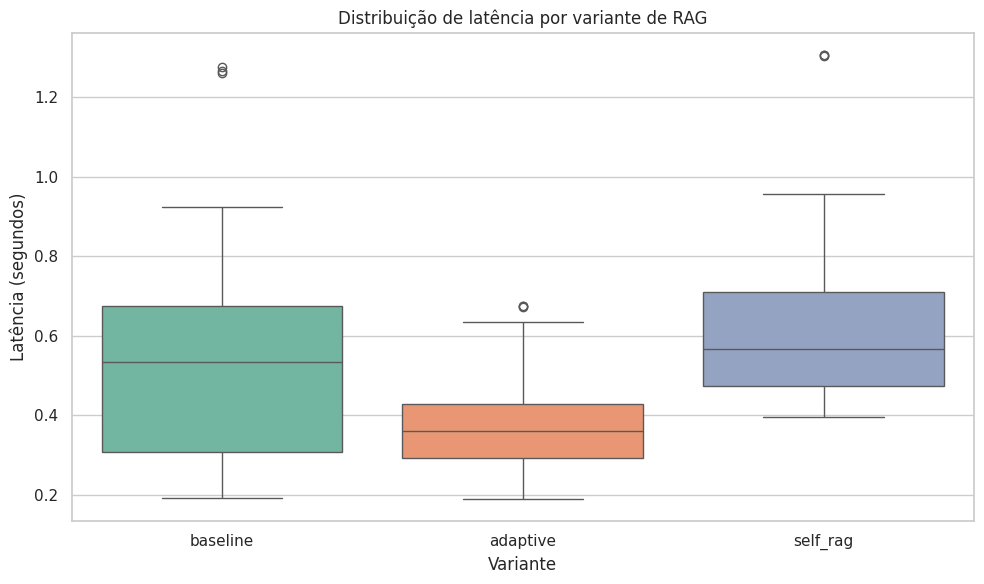

Figura gravada em: /content/results/imagem/boxplot_latencia.png


In [459]:
# CELULA 16
import seaborn as sns
import matplotlib.pyplot as plt

IMAGE_DIR = RESULTS_DIR / 'imagem'
IMAGE_DIR.mkdir(parents=True, exist_ok=True)

fig, ax = plt.subplots(figsize=(10, 6))
sns.boxplot(data=official_df, x='variant', y='latency_sec', hue='variant',
            palette='Set2', legend=False, ax=ax)
ax.set_title('Distribuição de latência por variante de RAG')
ax.set_xlabel('Variante')
ax.set_ylabel('Latência (segundos)')
fig.tight_layout()

out_png = IMAGE_DIR / 'boxplot_latencia.png'
fig.savefig(out_png, dpi=150)
plt.show()

assert out_png.exists(), f'Figura não gravada em {out_png}'
print('Figura gravada em:', out_png)

### 📊 Relatório Final Consolidado

Abaixo, geramos a tabela comparativa geral (tiers, chamadas de LLM e latência) e a análise visual mapeando corretamente os nomes para **baseline**, **Adaptive RAG** e **Self-RAG**.

In [461]:
import pandas as pd

name_mapping = {'baseline': 'baseline', 'adaptive': 'Adaptive RAG', 'self_rag': 'Self-RAG'}
ORDER = list(name_mapping.values())

# pré-verificação: falha antes de montar a tabela
required = {'variant', 'latency_sec', 'evidence_count', 'llm_calls', 'revised'}
missing = required - set(official_df.columns)
assert not missing, f'Colunas ausentes em official_df: {missing}'

df_mapped = official_df.copy()
# só o Self-RAG grava 'revised'; nas outras variantes o valor vira False.
# fillna precisa vir antes do astype: NaN convertido para bool vira True.
df_mapped['revised'] = df_mapped['revised'].fillna(False).astype(bool)
df_mapped['variant'] = df_mapped['variant'].map(name_mapping)

performance_table = (
    df_mapped.groupby('variant')
    .agg(
        latencia_media_seg=('latency_sec', 'mean'),
        chunks_medios_recuperados=('evidence_count', 'mean'),
        chamadas_llm_medias=('llm_calls', 'mean'),
        taxa_revisao=('revised', 'mean'),
    )
    .reindex(ORDER)
    .round(3)
    .reset_index()
)

assert not performance_table.isna().any().any(), 'Variante sem dados após o reindex.'

print('=== TABELA COMPARATIVA POR VARIANTE ===')
display(performance_table)

=== TABELA COMPARATIVA POR VARIANTE ===


/tmp/ipykernel_3568/2295219313.py:14: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  df_mapped['revised'] = df_mapped['revised'].fillna(False).astype(bool)


,variant,latencia_media_seg,chunks_medios_recuperados,chamadas_llm_medias,taxa_revisao
0,baseline,0.536,4.0,1.0,0.0
1,Adaptive RAG,0.373,4.0,1.0,0.0
2,Self-RAG,0.631,4.0,2.3,0.3


# Célula A: diagnóstico do baseline

1.   Esta célula monta a tabela das 20 perguntas, com acertos por variante, a resposta esperada e os 4 trechos recuperados pelo baseline na repetição 1.
2.   A coluna causa DEVE SER classificada com cada erro a partir da leitura dos trechos.
Não usa heurística lexical.




In [463]:
import json

TRACES = [json.loads(l) for l in open(TRACES_DIR / 'official_runs.jsonl', encoding='utf-8')]
tr = {(t['question_id'], t['variant'], t['repetition']): t for t in TRACES}

g = grades_df.copy()
g['ok'] = g['verdict'].eq('CORRECT')

acertos = (g.pivot_table(index='question_id', columns='variant', values='ok', aggfunc='sum')
             .astype(int).add_suffix('_acertos_de_3'))

dif = g.drop_duplicates('question_id').set_index('question_id')['difficulty']

diag = acertos.join(dif)
diag.insert(0, 'gabarito', pd.Series({q: key_map[q] for q in diag.index}))

# baseline, repetição 1: trechos recuperados, truncados para leitura
def trechos(qid):
    t = tr[(qid, 'baseline', 1)]
    return ' || '.join(f"[{e['rank']}] {e['text'][:200]}" for e in t['evidence'])

diag['trechos_baseline_rep1'] = [trechos(q) for q in diag.index]
diag['causa (preencher)'] = ''

diag = diag.reset_index()
diag.to_csv(RESULTS_DIR / 'diagnostico_baseline.csv', index=False)
display(diag)

,question_id,gabarito,adaptive_acertos_de_3,baseline_acertos_de_3,self_rag_acertos_de_3,difficulty,trechos_baseline_rep1,causa (preencher)
0,Q01,"ML systems learn from data, so data quality an...",3,3,3,easy,[1] having a large amount of data over intelli...,
1,Q02,The book describes the data-centric vs model-c...,3,0,0,easy,[1] o discuss a high-level debate that has con...,
2,Q03,"A simple baseline is cheap and fast, sets a re...",3,3,3,easy,[1] lity (50%) 0.167 0.5 Task’s label distribu...,
3,Q04,Label noise teaches the model wrong correlatio...,0,0,0,medium,[1] distribution will differ from your trainin...,
4,Q05,Hidden feedback loops occur when model predict...,0,0,0,medium,[1] for the model as discussed in Chapter 4 — ...,
5,Q06,"Data monitoring signals: distribution shift, d...",0,0,0,medium,"[1] ry. Before we move on to the next chapter,...",
6,Q07,Pre-deployment evaluation uses offline metrics...,3,3,3,medium,"[1] at random, which meant it probably didn’t ...",
7,Q08,Aggregate metrics average out failures concent...,3,3,3,medium,"[1] e on average, confidence measurement is a ...",
8,Q09,Train-serving skew: when features are computed...,3,3,3,medium,[1] ollars in building ML systems to learn tho...,
9,Q10,Lower latency usually costs more compute or si...,0,0,0,medium,"[1] to run a batch, the average latency is sti...",


# Célula B: sinal versus ruído
Esta célula mostra a acurácia de cada repetição e a média com desvio padrão entre repetições. Com 3 repetições, o desvio padrão é instável, então trate as barras de erro como indicação, não como intervalo de confiança.

repetition,1,2,3
variant,,,
baseline,0.3,0.3,0.3
adaptive,0.4,0.4,0.4
self_rag,0.3,0.3,0.3


,media,desvio_padrao
variant,,
baseline,0.3,0.0
adaptive,0.4,0.0
self_rag,0.3,0.0


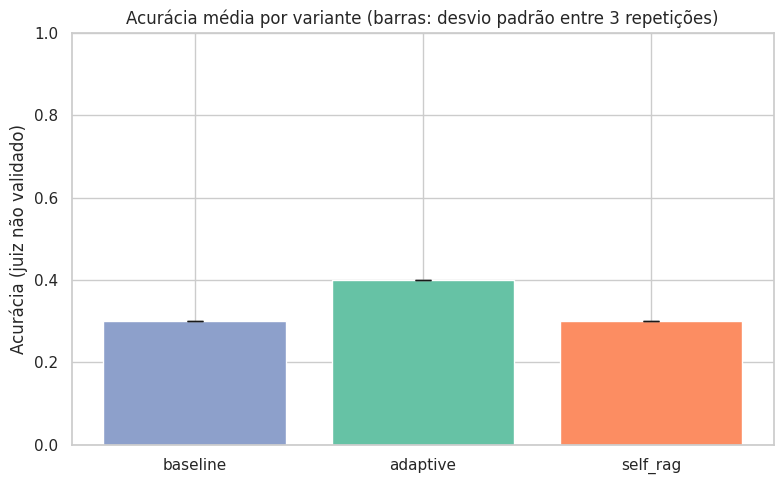

In [464]:
import matplotlib.pyplot as plt

por_rep = g.groupby(['variant', 'repetition'])['ok'].mean().reset_index()
por_rep = por_rep.rename(columns={'ok': 'acuracia'})

resumo_var = (por_rep.groupby('variant')['acuracia']
              .agg(media='mean', desvio_padrao='std')
              .reindex(['baseline', 'adaptive', 'self_rag'])
              .round(3))
display(por_rep.pivot(index='variant', columns='repetition', values='acuracia')
        .reindex(['baseline', 'adaptive', 'self_rag']).round(3))
display(resumo_var)

IMAGE_DIR = RESULTS_DIR / 'imagem'
IMAGE_DIR.mkdir(parents=True, exist_ok=True)

fig, ax = plt.subplots(figsize=(8, 5))
ax.bar(resumo_var.index, resumo_var['media'], yerr=resumo_var['desvio_padrao'],
       capsize=6, color=['#8da0cb', '#66c2a5', '#fc8d62'])
ax.set_ylim(0, 1)
ax.set_ylabel('Acurácia (juiz não validado)')
ax.set_title('Acurácia média por variante (barras: desvio padrão entre 3 repetições)')
fig.tight_layout()
fig.savefig(IMAGE_DIR / 'acuracia_sinal_ruido.png', dpi=150)
plt.show()

# Célula C: divergências entre variantes
Esta célula lista as perguntas em que as variantes divergem na mesma repetição, junto com as respostas. Essa é a lista que o item 3 pede, com as causas a serem registradas com base na célula A.

In [465]:
piv = g.pivot_table(index=['question_id', 'repetition'], columns='variant',
                    values='ok', aggfunc='first')
div = piv[piv.nunique(axis=1) > 1]

ans = official_df.pivot_table(index=['question_id', 'repetition'], columns='variant',
                              values='answer', aggfunc='first').add_suffix('_resposta')

divergencias = div.join(ans).reset_index()
divergencias.to_csv(RESULTS_DIR / 'divergencias_variantes.csv', index=False)
print(f'{len(divergencias)} linhas com divergência entre variantes.')
display(divergencias)

6 linhas com divergência entre variantes.


variant,question_id,repetition,adaptive,baseline,self_rag,adaptive_resposta,baseline_resposta,self_rag_resposta
0,Q02,1,True,False,False,The book describes a debate in the ML literatu...,The book describes a debate within the machine...,The book describes a debate within the machine...
1,Q02,2,True,False,False,The book describes a debate in the ML literatu...,The book describes a debate within the machine...,The book describes a debate within the machine...
2,Q02,3,True,False,False,The book describes a debate in the ML literatu...,The book describes a debate within the machine...,The book describes a debate within the machine...
3,Q12,1,True,False,False,Monitoring and logging are crucial in ML syste...,The provided context does not contain explicit...,The context provided does not contain specific...
4,Q12,2,True,False,False,Monitoring and logging are crucial in ML syste...,The provided context does not contain explicit...,The context provided does not contain specific...
5,Q12,3,True,False,False,Monitoring and logging are crucial in ML syste...,The provided context does not contain explicit...,The context provided does not contain specific...


# Chamadas ao LLM e latência por dificuldade (visualização)

A figura abaixo traz dois painéis. No primeiro, a média de chamadas ao LLM por variante: 1,0 para baseline e Adaptive RAG, e cerca de 2,3 para o Self-RAG, que faz uma chamada de rascunho e verificação e, quando há revisão, uma chamada adicional. No segundo, a latência média por nível de dificuldade (fácil, médio e difícil), separada por variante.

![Média de chamadas ao LLM e latência média por dificuldade](imagem/chamadas_e_latencia.png)

**Leitura:** o número de chamadas explica boa parte da diferença de latência entre o Self-RAG e as demais variantes. Como as variantes foram executadas em blocos sequenciais, com aquecimento antes de cada uma, diferenças de latência também podem refletir o estado do servidor. Os grupos de dificuldade têm tamanhos diferentes (15, 12 e 33 execuções por variante, conforme a distribuição do corpus), então comparações entre níveis devem considerar o tamanho amostral.

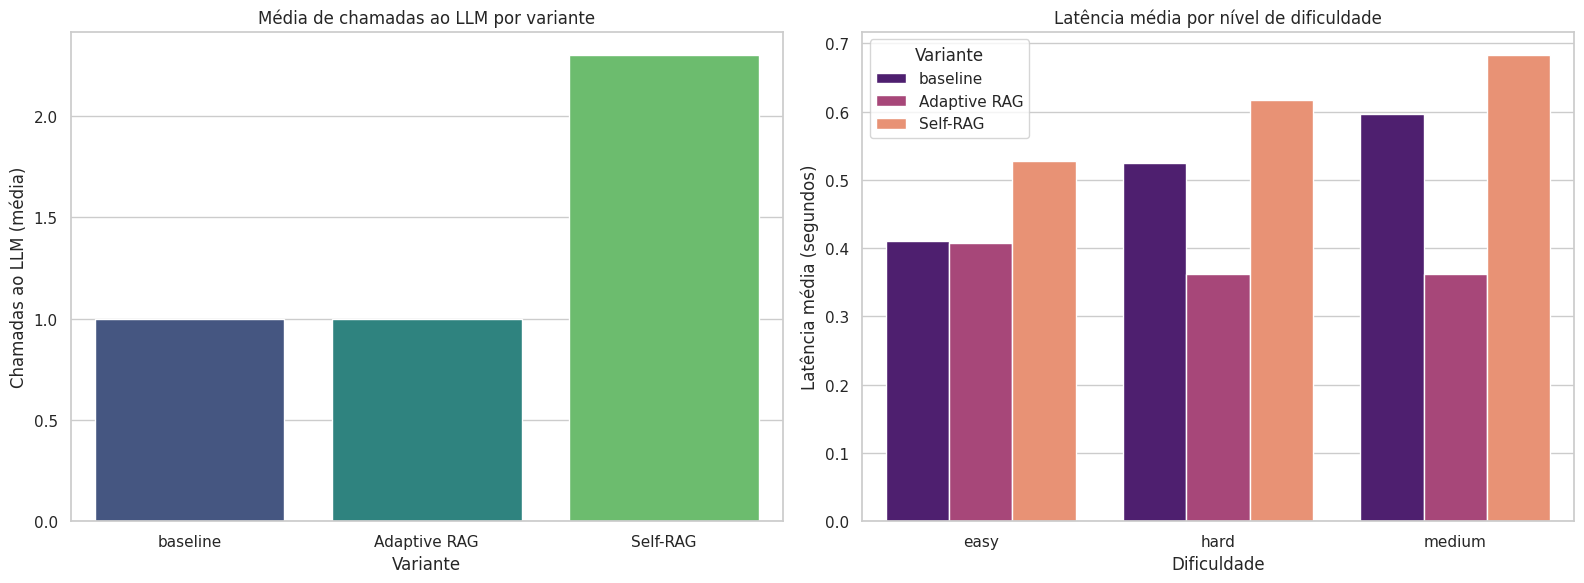

Figura gravada em: /content/results/imagem/chamadas_e_latencia.png


In [466]:
import seaborn as sns
import matplotlib.pyplot as plt

ORDER = ['baseline', 'Adaptive RAG', 'Self-RAG']
IMAGE_DIR = RESULTS_DIR / 'imagem'
IMAGE_DIR.mkdir(parents=True, exist_ok=True)

# pré-verificação: falha se a célula 17 corrigida não foi rodada
assert 'chamadas_llm_medias' in performance_table.columns, 'Rode a célula 17 corrigida antes.'
assert set(df_mapped['variant'].unique()) == set(ORDER), 'Nomes de variante não batem com ORDER.'

latency_diff = df_mapped.groupby(['variant', 'difficulty'], as_index=False)['latency_sec'].mean()

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

sns.barplot(data=performance_table, x='variant', y='chamadas_llm_medias',
            order=ORDER, hue='variant', hue_order=ORDER, palette='viridis',
            legend=False, ax=axes[0])
axes[0].set_title('Média de chamadas ao LLM por variante')
axes[0].set_xlabel('Variante')
axes[0].set_ylabel('Chamadas ao LLM (média)')

sns.barplot(data=latency_diff, x='difficulty', y='latency_sec',
            hue='variant', hue_order=ORDER, palette='magma', ax=axes[1])
axes[1].set_title('Latência média por nível de dificuldade')
axes[1].set_xlabel('Dificuldade')
axes[1].set_ylabel('Latência média (segundos)')
axes[1].legend(title='Variante')

fig.tight_layout()
out_png = IMAGE_DIR / 'chamadas_e_latencia.png'
fig.savefig(out_png, dpi=150)
plt.show()

assert out_png.exists(), f'Figura não gravada em {out_png}'
print('Figura gravada em:', out_png)

### 🎯 Avaliação Qualitativa das Chamadas

Para avaliar quantitativamente a qualidade semântica das respostas de cada variante, analisamos:
- **Tamanho médio das respostas (caracteres)**: Respostas muito curtas podem indicar falta de informação, enquanto respostas longas demais podem trazer ruído.
- **Taxa de Alucinação / Respostas Negativas**: Frequência de respostas onde o modelo explicitamente diz que não pôde responder por falta de contexto (ex: *"say so explicitly"* ou *"not enough evidence"*).

In [467]:
# 1. Analisar comprimento médio das respostas geradas
df_mapped['answer_length'] = df_mapped['answer'].astype(str).str.len()

# 2. Identificar se o modelo admitiu não ter informação no corpus (Abstenção/Fallback)
fallback_phrases = ['not enough evidence', 'does not contain', 'não encontrei', 'insufficiente', 'no initial evidence']
df_mapped['fallback_triggered'] = df_mapped['answer'].astype(str).str.lower().apply(
    lambda x: any(phrase in x for phrase in fallback_phrases)
)

quality_summary = df_mapped.groupby('variant').agg(
    comprimento_medio_caracteres=('answer_length', 'mean'),
    taxa_abstencao_fallback=('fallback_triggered', 'mean')
).reindex(['baseline', 'Adaptive RAG', 'Self-RAG']).reset_index()

print("=== MÉTRICAS DE QUALIDADE DAS RESPOSTAS ===")
display(quality_summary)

=== MÉTRICAS DE QUALIDADE DAS RESPOSTAS ===


,variant,comprimento_medio_caracteres,taxa_abstencao_fallback
0,baseline,685.700000,0.20
1,Adaptive RAG,468.233333,0.55
2,Self-RAG,663.216667,0.10


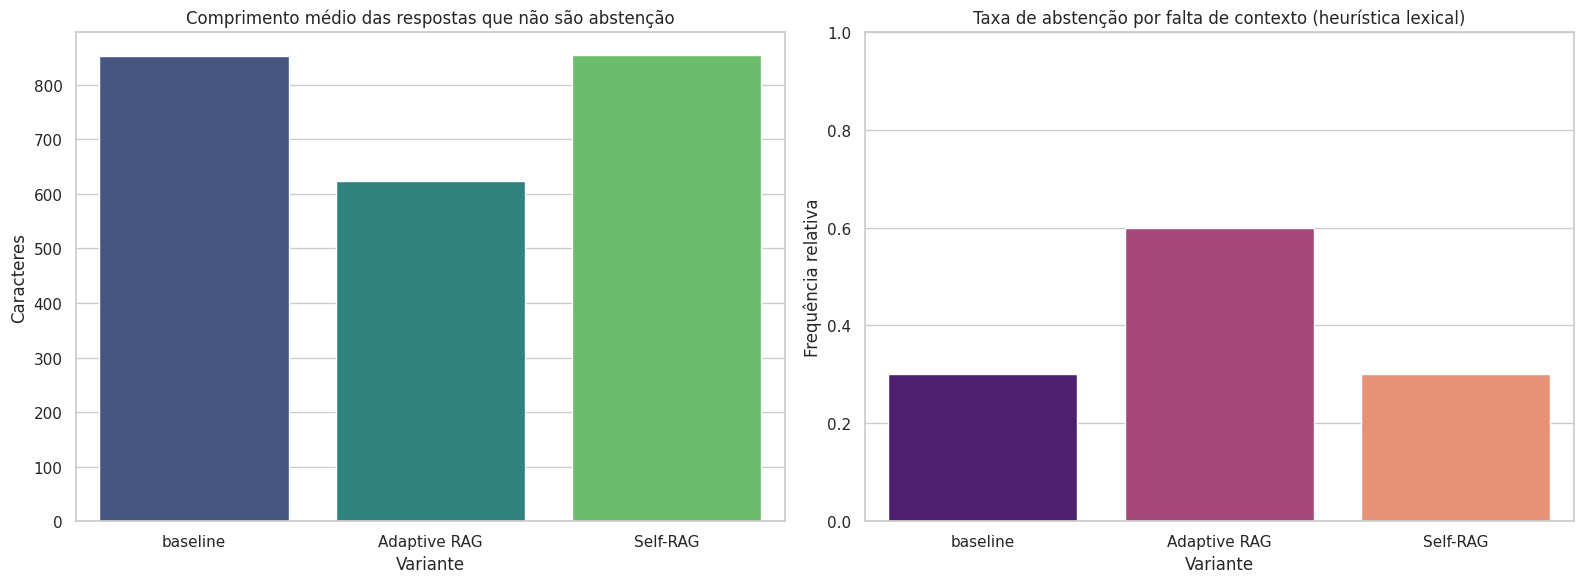

Figura gravada em: /content/results/imagem/qualidade_respostas.png
     variant  taxa_abstencao  comprimento_respondido
    baseline             0.3                 851.714
Adaptive RAG             0.6                 623.375
    Self-RAG             0.3                 854.095


In [473]:
import re
import seaborn as sns
import matplotlib.pyplot as plt

ORDER = ['baseline', 'Adaptive RAG', 'Self-RAG']
IMAGE_DIR = RESULTS_DIR / 'imagem'
IMAGE_DIR.mkdir(parents=True, exist_ok=True)

# mesma expressão da checagem cruzada, aplicada ao texto original
MAP = {'baseline': 'baseline', 'adaptive': 'Adaptive RAG', 'self_rag': 'Self-RAG'}
q = official_df.assign(
    variant=official_df['variant'].map(MAP),
    answer_length=official_df['answer'].astype(str).str.len(),
    abstencao=official_df['answer'].astype(str).apply(lambda x: bool(FALLBACK_RE.search(x))),
)

qs = q.groupby('variant').agg(
    taxa_abstencao=('abstencao', 'mean'),
    comprimento_respondido=('answer_length', lambda s: s[~q.loc[s.index, 'abstencao']].mean()),
).reindex(ORDER).reset_index()

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

sns.barplot(data=qs, x='variant', y='comprimento_respondido', order=ORDER,
            hue='variant', hue_order=ORDER, palette='viridis', legend=False, ax=axes[0])
axes[0].set_title('Comprimento médio das respostas que não são abstenção')
axes[0].set_xlabel('Variante')
axes[0].set_ylabel('Caracteres')

sns.barplot(data=qs, x='variant', y='taxa_abstencao', order=ORDER,
            hue='variant', hue_order=ORDER, palette='magma', legend=False, ax=axes[1])
axes[1].set_title('Taxa de abstenção por falta de contexto (heurística lexical)')
axes[1].set_xlabel('Variante')
axes[1].set_ylabel('Frequência relativa')
axes[1].set_ylim(0, 1)

fig.tight_layout()
out_png = IMAGE_DIR / 'qualidade_respostas.png'
fig.savefig(out_png, dpi=150)
plt.show()

assert out_png.exists(), f'Figura não gravada em {out_png}'
print('Figura gravada em:', out_png)
print(qs.round(3).to_string(index=False))

#### 4. Conclusões e análise de sinal vs. ruído

**Acurácia e trade-off.** Com o juiz `llama3.1:8b` (não validado), a acurácia é de 30% no baseline, 40% no Adaptive RAG e 30% no Self-RAG. O Adaptive é o único com ganho, e o ganho vem da abstenção: ele responde menos (60% das execuções são abstenções pela expressão regular) e acerta todas as respostas que dá (24 de 24). Nas outras variantes, 43% das respostas não abstencionistas estão corretas (18 de 42). Ou seja, o Adaptive troca cobertura por precisão; ele não recupera melhor.

**Custo.** O Self-RAG faz em média 2 a 3 chamadas ao LLM por pergunta, contra 1 do baseline e do Adaptive. Essas chamadas adicionais não aumentaram a acurácia em relação ao baseline (30% em ambos). A latência maior do Self-RAG é consequência direta das chamadas extras e não se traduziu em ganho de qualidade nesta execução.

**Divergências entre variantes.** Na mesma repetição, as variantes divergem principalmente pela presença de abstenção: nas perguntas em que o Adaptive acerta e o baseline erra, a diferença está em respostas que o baseline dá com conteúdo errado ou incompleto. A causa dessas diferenças não foi demonstrada. Não medimos similaridade textual, então não afirmamos que as divergências são ruído de amostragem.

**Sinal versus ruído.** A estabilidade entre as três repetições é o critério para separar sinal de ruído. Uma diferença entre variantes só é tratada como sinal se se mantém nas três repetições, e a leitura deve vir de `acuracia_sinal_ruido.png` e da tabela por repetição. Com 3 repetições por pergunta e 20 perguntas, o desvio padrão é uma indicação, não um intervalo de confiança.

**Limitações.**
- O juiz automático não foi validado contra avaliação manual; os valores de acurácia são exploratórios.
- A abstenção é medida por expressão regular, uma heurística lexical. Respostas com ressalva podem estar classificadas como abstenção.
- O corpus tem 20 perguntas, e o resultado pode não generalizar.
- Os valores de latência devem ser lidos na aba Resumo e no boxplot, sem interpretação de causa.